# Screens, With Libraries
# Alex Beene
# Oct 2026

Some parameters to tweak: **epochs, neurons, learning rate**. These are real basketball possessions, so there is a bit more complexity here to prep you for Module 7.
100% is not possible or the goal (remember overfitting)

## 1. What a screen looks like as numbers

`data/asu_ndsu_screen_plays/` holds five possessions from Arkansas State vs NDSU Men's Basketball.
Each `.csv` is one row per player (or ball) per frame, 30 frames a second, with
`x_ft` / `y_ft` in court feet. Someone already turned the broadcast into dots —

The `.mp4` with the same name is there if you want to watch the play. Frame 415 of
the 11:08 clip is a ball screen

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("data/p1_11m08-10m53_astate_ndsu.csv")
frame = raw[(raw.frame == 415) & raw.x_ft.notna()]
frame[["object", "player_id", "team", "x_ft", "y_ft", "ball_state", "ball_held_by"]]

,object,player_id,team,x_ft,y_ft,ball_state,ball_held_by
3586,player,w1,Arkansas State,66.5,11.8,NaN,NaN
3587,player,w?b,Arkansas State,69.7,22.1,NaN,NaN
3588,player,w?a,Arkansas State,78.2,35.9,NaN,NaN
3589,player,w0,Arkansas State,78.6,12.5,NaN,NaN
3590,player,w10,Arkansas State,82.1,25.8,NaN,NaN
3591,player,g0,North Dakota State,64.7,38.7,NaN,NaN
3592,player,g30,North Dakota State,66.4,13.4,NaN,NaN
3593,player,g1,North Dakota State,67.5,7.8,NaN,NaN
3594,player,g34,North Dakota State,85.1,30.3,NaN,NaN
3595,player,g3,North Dakota State,86.8,49.4,NaN,NaN


In [3]:
from matplotlib.patches import Arc, Circle, Rectangle

def draw_court(ax, half="right", color="0.55", lw=1.2):
    """NCAA men's court in the tracking data's feet: x 0..94 baseline to baseline,
    y 0..50 sideline to sideline. half = "right", "left", or "full"."""
    kw = dict(color=color, lw=lw, fill=False, zorder=1)
    ax.add_patch(Rectangle((0, 0), 94, 50, **kw))                  # boundary
    ax.plot([47, 47], [0, 50], c=color, lw=lw, zorder=1)           # half-court line
    ax.add_patch(Circle((47, 25), 6, **kw))                        # center circle
    for base, d in [(0, 1), (94, -1)]:                             # each end, mirrored
        rim = base + d * 5.25
        ax.add_patch(Rectangle((min(base, base + d * 19), 19), 19, 12, **kw))   # lane, 12 ft wide
        ax.add_patch(Circle((base + d * 19, 25), 6, **kw))         # free-throw circle
        ax.plot([base + d * 4] * 2, [22, 28], c=color, lw=2, zorder=1)          # backboard
        ax.add_patch(Circle((rim, 25), 0.75, **kw))                # rim
        a = 0 if d == 1 else 180
        ax.add_patch(Arc((rim, 25), 8, 8, theta1=a - 90, theta2=a + 90, **kw))  # restricted area
        # three-point line: 22' 1.75" arc, straight 21' 7.875" from the rim in the corners
        r, corner = 22.146, 21.65
        straight = np.sqrt(r**2 - corner**2)                       # ~4.7 ft past the rim
        for y in (25 - corner, 25 + corner):
            ax.plot([base, rim + d * straight], [y, y], c=color, lw=lw, zorder=1)
        open_ang = np.degrees(np.arcsin(corner / r))
        ax.add_patch(Arc((rim, 25), 2 * r, 2 * r, theta1=a - open_ang, theta2=a + open_ang, **kw))
    xlim = {"right": (47, 94), "left": (0, 47), "full": (0, 94)}[half]
    ax.set_xlim(xlim[0] - 1, xlim[1] + 1); ax.set_ylim(-1, 51)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    return ax

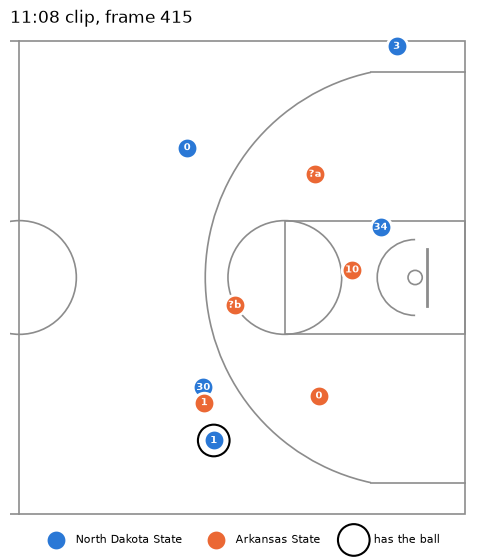

In [4]:
OFF, DEF = "#2a78d6", "#eb6834"      # NDSU has the ball in all five clips

fig, ax = plt.subplots(figsize=(6, 6.4))
draw_court(ax, half="right")
for team, color in [("North Dakota State", OFF), ("Arkansas State", DEF)]:
    p = frame[frame.team == team]
    ax.scatter(p.x_ft, p.y_ft, s=220, c=color, edgecolor="white", linewidth=2, label=team, zorder=3)
    for _, r in p.iterrows():
        ax.annotate(r.player_id[1:], (r.x_ft, r.y_ft), ha="center", va="center",
                    fontsize=7, color="white", weight="bold", zorder=4)
handler = frame[frame.player_id == frame.ball_held_by.dropna().iloc[0]]
ax.scatter(handler.x_ft, handler.y_ft, s=520, facecolor="none", edgecolor="black", linewidth=1.5,
           zorder=2, label="has the ball")
ax.set_title("11:08 clip, frame 415", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(.5, 0), ncol=3, frameon=False, fontsize=8)
plt.show()

**Answer the following:** could you train a network on these five clips
to recognize a screen?

## 2. Borrow the labels

`data/pnr_windows.csv` is the file from the Neural Net Assignment: six Spanish pro games,
every pick tagged by a tracking vendor, 52 columns of raw geometry around the ball
handler. We will train on five games, test on the sixth.

In [15]:
from screen_features import FEATURES
from sklearn.preprocessing import StandardScaler

acb = pd.read_csv("data/pnr_windows.csv")
train, test = acb[acb.game_id != 189885], acb[acb.game_id == 189885]

scaler = StandardScaler().fit(train[FEATURES])
X_train, y_train = scaler.transform(train[FEATURES]), train.is_pick.values
X_test,  y_test  = scaler.transform(test[FEATURES]),  test.is_pick.values

print("train", X_train.shape, " test", X_test.shape)
print("baseline (always say 'no pick') on test:", round(1 - y_test.mean(), 3))

pd.DataFrame(y_train)

train (2771, 52)  test (734, 52)
baseline (always say 'no pick') on test: 0.804


,0
0,1
1,1
2,1
3,1
4,1
...,...
2766,0
2767,0
2768,0
2769,0


## 3. Build it

Same `build` you have seen all module. 

On XOR there was no held-out anything. This is the difference between you're XOR dataset you are learning on and real world data (like Module 7 will be).

In [16]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

def build(neurons=16, lr=0.001, seed=0):
    tf.keras.utils.set_random_seed(seed)
    m = Sequential([Input(shape=(52,)),
                    Dense(neurons, activation="relu"),
                    Dense(1, activation="sigmoid")])
    m.compile(optimizer=Adam(learning_rate=lr),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

def scores(m):
    tr = m.predict(X_train, verbose=0).ravel() >= .5
    te = m.predict(X_test,  verbose=0).ravel() >= .5
    return {"train acc": (tr == y_train).mean(),
            "test acc":  (te == y_test).mean(),
            "pick recall": te[y_test == 1].mean()}

# Build the model to test our functions

## 4. Parameter 1 — epochs

Two seeds per setting, since this will take a minute or 2.

Training model with 5 epochs, train acc=0.8802, test acc=0.8597
Training model with 25 epochs, train acc=0.9610, test acc=0.9155
Training model with 100 epochs, train acc=0.9960, test acc=0.9237
Training model with 300 epochs, train acc=0.9989, test acc=0.9223


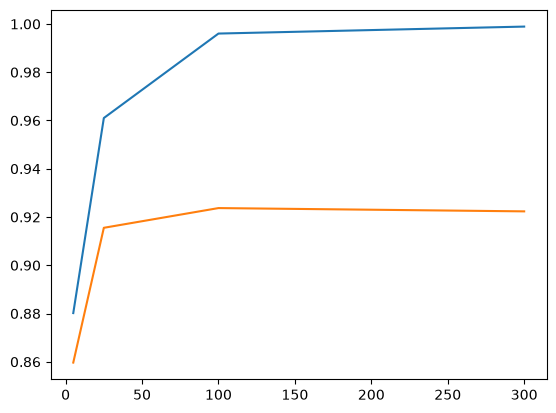

In [19]:
epochs_list = [5, 25, 100, 300]
train_accs_list = []
test_accs_list = []

for epochs in epochs_list:
    model = build()
    model.fit(X_train, y_train, epochs=epochs, verbose=0)
    s=scores(model)
    train_acc = s['train acc']
    test_acc = s['test acc']
    print(f'Training model with {epochs} epochs, train acc={train_acc:.4f}, test acc={test_acc:.4f}')
    train_accs_list.append(train_acc)
    test_accs_list.append(test_acc)

plt.plot(epochs_list, train_accs_list)
plt.plot(epochs_list, test_accs_list)



Training accuracy? Held-out accuracy?

## 5. Parameter 2 — neurons in the hidden layer

One neuron is a straight line through 52-dimensional space — a logistic regression
with extra steps.

NN w/ Parameters Assignment: is the network failing because the **search**
is bad, or because the **model is too small**? Look at what 1 neuron does across
seeds.

## 6. Parameter 3 — learning rate (you try!)

Write the loop. Try at least `0.0001, 0.001, 0.01, 0.1`, two seeds each, 50 epochs,
16 neurons. Before you run it, write down which one you expect to win.

Training model with learning rate 0.0001, seed 1, train acc=0.9141, test acc=0.8787
Training model with learning rate 0.001, seed 1, train acc=0.9939, test acc=0.9264
Training model with learning rate 0.01, seed 1, train acc=0.9949, test acc=0.9196
Training model with learning rate 0.1, seed 1, train acc=0.9830, test acc=0.9278


(0.0, 0.1)

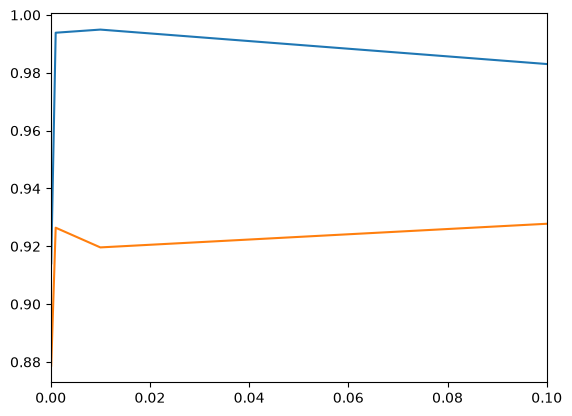

In [ ]:
# YOUR CODE HERE 
learning_rates = [0.0001, 0.001, 0.01, 0.1]

train_accs_list=[]
test_accs_list=[]

for lr in learning_rates:
        model = build(neurons=16, lr=lr, seed=seed)
        model.fit(X_train, y_train, epochs=100, verbose=0)
        s=scores(model)
        train_acc=s['train acc']
        test_acc=s['test acc']
        train_accs_list.append(train_acc)
        test_accs_list.append(test_acc)
        print(f'Training model with learning rate {lr}, seed {seed}, train acc={train_acc:.4f}, test acc={test_acc:.4f}')

plt.plot(learning_rates, train_accs_list)
plt.plot(learning_rates, test_accs_list)

**Question:** which learning rate won, was it the one you predicted, and what
happened at the slowest setting after 50 epochs? (Hint: compare it to 5 epochs in
the epochs table.)

## 7. Point it at a college game (if time)

The model has never seen NCAA basketball, Arkansas State, or NDSU. `screen_features.py`
turns each of the five clips into the same 52 columns, one row per frame. Then we ask
the trained model, frame by frame: is this a pick?

In [ ]:
from screen_features import load_all_clips

clips = load_all_clips("data/asu_ndsu_screen_plays")
model = build(neurons=16, seed=0)
model.fit(X_train, y_train, epochs=100, batch_size=64, verbose=0)
clips["p_pick"] = model.predict(scaler.transform(clips[FEATURES]), verbose=0).ravel()

clips.groupby("clip").agg(frames=("frame", "size"), share_flagged=("p_pick", lambda p: (p >= .5).mean())).round(2)

In [ ]:
names = sorted(clips["clip"].unique())
fig, axes = plt.subplots(len(names), 1, figsize=(8, 7), sharex=True)
for ax, name in zip(axes, names):
    c = clips[clips["clip"] == name]
    ax.plot(c.t_clip_s, c.p_pick, ".", c=OFF, ms=2)
    ax.axhline(.5, c="0.6", lw=1, ls="--")
    ax.set_ylim(-.05, 1.05); ax.set_yticks([0, .5, 1])
    ax.set_title(f"{name[3:8].replace('m', ':')} clip", loc="left", fontsize=9)
    ax.grid(alpha=.2)
axes[-1].set_xlabel("seconds into the clip")
fig.suptitle("Probability of a pick, every frame (dashed line = 0.5)", x=.01, ha="left")
plt.tight_layout(); plt.show()

Now, every stretch the model held above 0.5 for at least a third of a second,
with the frame number so you can find it in the video

In [ ]:
def flagged_windows(c, thresh=.5, min_frames=10, gap=15):
    hits = c[c.p_pick >= thresh]
    if hits.empty:
        return []
    breaks = np.where(np.diff(hits.frame.values) > gap)[0]
    starts = np.r_[0, breaks + 1]; ends = np.r_[breaks, len(hits) - 1]
    out = []
    for s, e in zip(starts, ends):
        h = hits.iloc[s:e + 1]
        if h.frame.iloc[-1] - h.frame.iloc[0] + 1 >= min_frames:
            out.append({"clip": c["clip"].iloc[0], "first frame": h.frame.iloc[0], "last frame": h.frame.iloc[-1],
                        "game clock": h.game_clock.iloc[0], "peak p": round(h.p_pick.max(), 2)})
    return out

windows = pd.DataFrame([w for name in names for w in flagged_windows(clips[clips["clip"] == name])])
windows

,clip,first frame,last frame,game clock,peak p
0,p1_05m41-05m16_astate_ndsu,305,316,5:30.9,0.81
1,p1_05m41-05m16_astate_ndsu,597,621,5:21.1,0.90
2,p1_07m22-06m58_astate_ndsu,137,171,7:17.5,0.99
3,p1_07m22-06m58_astate_ndsu,457,484,7:06.8,0.99
4,p1_10m32-10m07_astate_ndsu,102,146,10:28.6,1.00
5,p1_10m32-10m07_astate_ndsu,486,521,10:15.8,0.94
6,p1_10m32-10m07_astate_ndsu,598,614,10:12.1,0.97
7,p1_11m08-10m53_astate_ndsu,389,415,10:55.1,0.93


## 8. Check out the video

Pick two rows from that table. For each one, open the matching `.mp4`, go to that
frame and watch.

- Was it an on-ball screen? An off-ball screen? Something else?
- Is there a screen in that clip the model **didn't** flag?